# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Daffa Aufa Afif | 5054251022 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.


# 1. Persiapan Dataset dan Eksplorasi Awal


In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import random
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)

# Set random seed agar hasil eksperimen deterministik dan dapat direproduksi
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('Churn_Modelling.csv')
display(df.head())

df.info()
missing_summary = df.isnull().sum()
print(missing_summary)

display(df.describe())


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gend

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


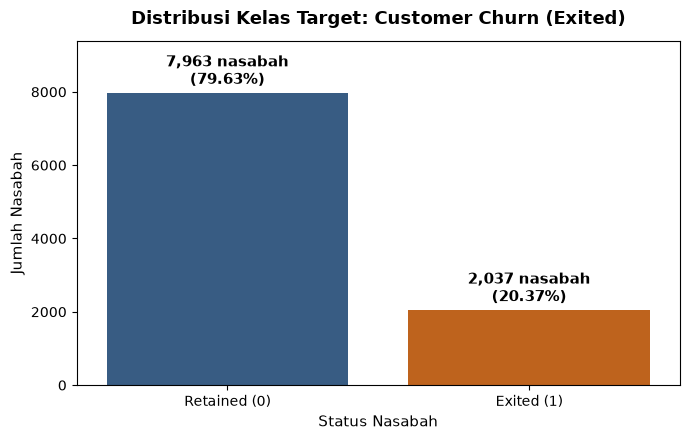

Rincian distribusi kelas target:
- Retained (0) : 7,963 nasabah (79.63%)
- Exited (1)   : 2,037 nasabah (20.37%)
- Rasio Kelas Mayoritas terhadap Minoritas : 3.91 : 1


In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
counts = df['Exited'].value_counts().sort_index()
pcts = df['Exited'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
palette = ['#2b5c8f', '#d95f02']
bars = sns.barplot(x=['Retained (0)', 'Exited (1)'], y=counts.values, ax=ax, palette=palette, hue=['Retained (0)', 'Exited (1)'], legend=False)

ax.set_title('Distribusi Kelas Target: Customer Churn (Exited)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Status Nasabah', fontsize=11)
ax.set_ylabel('Jumlah Nasabah', fontsize=11)
ax.set_ylim(0, counts.max() * 1.18)

for i, (count, pct) in enumerate(zip(counts, pcts)):
    ax.text(i, count + 120, f'{count:,} nasabah\n({pct:.2f}%)', ha='center', va='bottom', fontsize=10.5, fontweight='bold')

plt.tight_layout()
plt.show()

print("Rincian distribusi kelas target:")
print(f"- Retained (0) : {counts[0]:,} nasabah ({pcts[0]:.2f}%)")
print(f"- Exited (1)   : {counts[1]:,} nasabah ({pcts[1]:.2f}%)")
print(f"- Rasio Kelas Mayoritas terhadap Minoritas : {counts[0]/counts[1]:.2f} : 1")


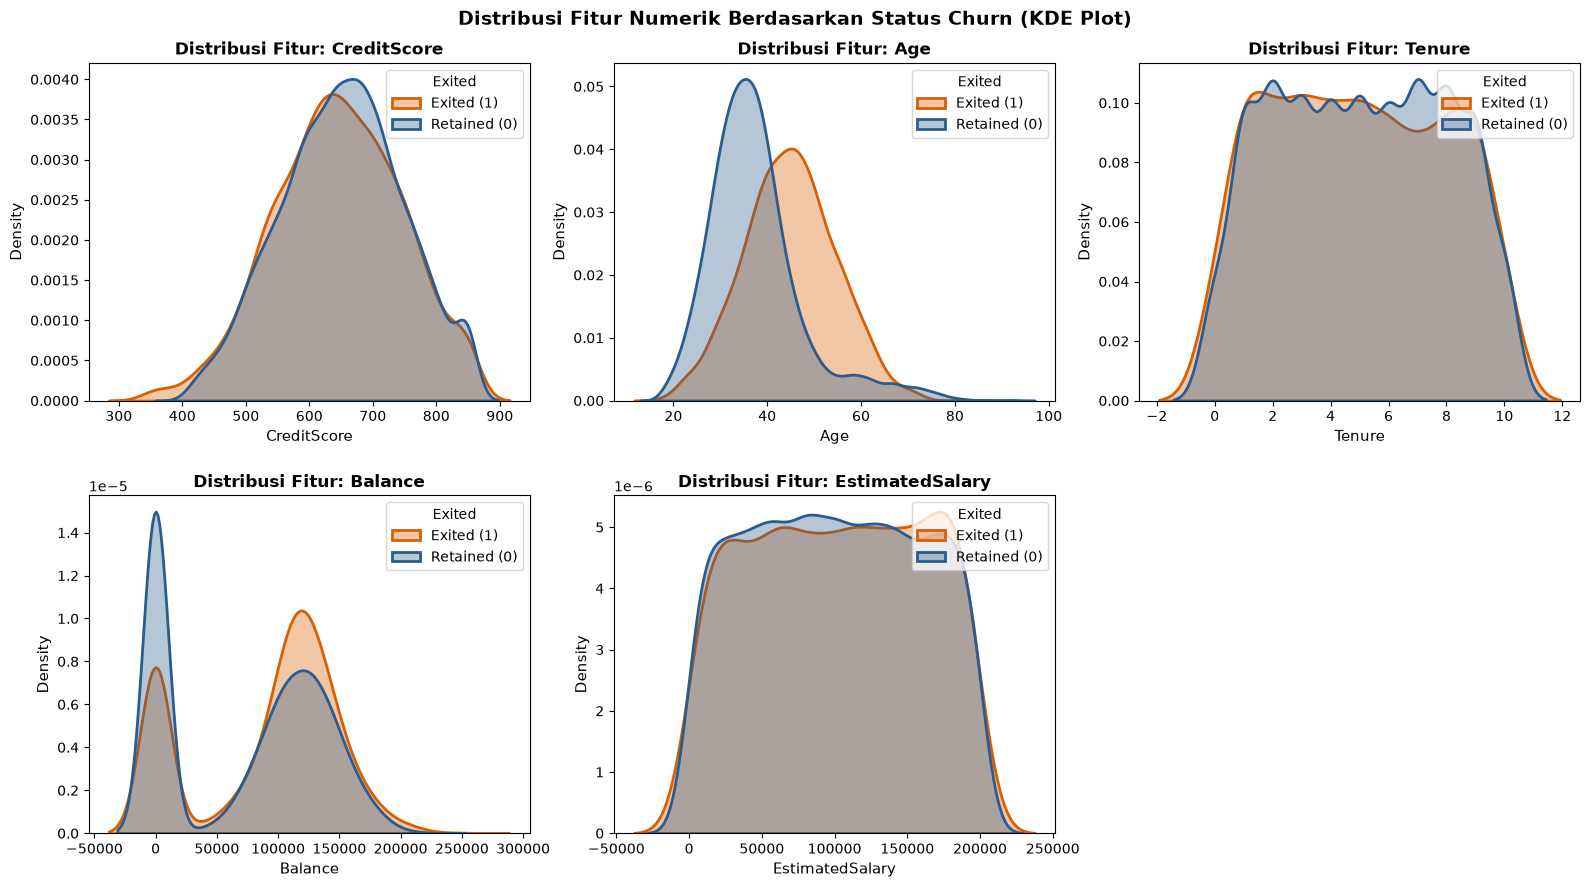

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
num_eda = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(num_eda):
    sns.kdeplot(
        data=df, x=col, hue='Exited', common_norm=False, fill=True,
        ax=axes[i], palette=['#2b5c8f', '#d95f02'], alpha=0.35, linewidth=2
    )
    axes[i].set_title(f'Distribusi Fitur: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10.5)
    axes[i].set_ylabel('Density', fontsize=10.5)
    axes[i].legend(title='Exited', labels=['Exited (1)', 'Retained (0)'], loc='upper right')

# Hapus subplot kosong ke-6
fig.delaxes(axes[5])

plt.suptitle('Distribusi Fitur Numerik Berdasarkan Status Churn (KDE Plot)', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


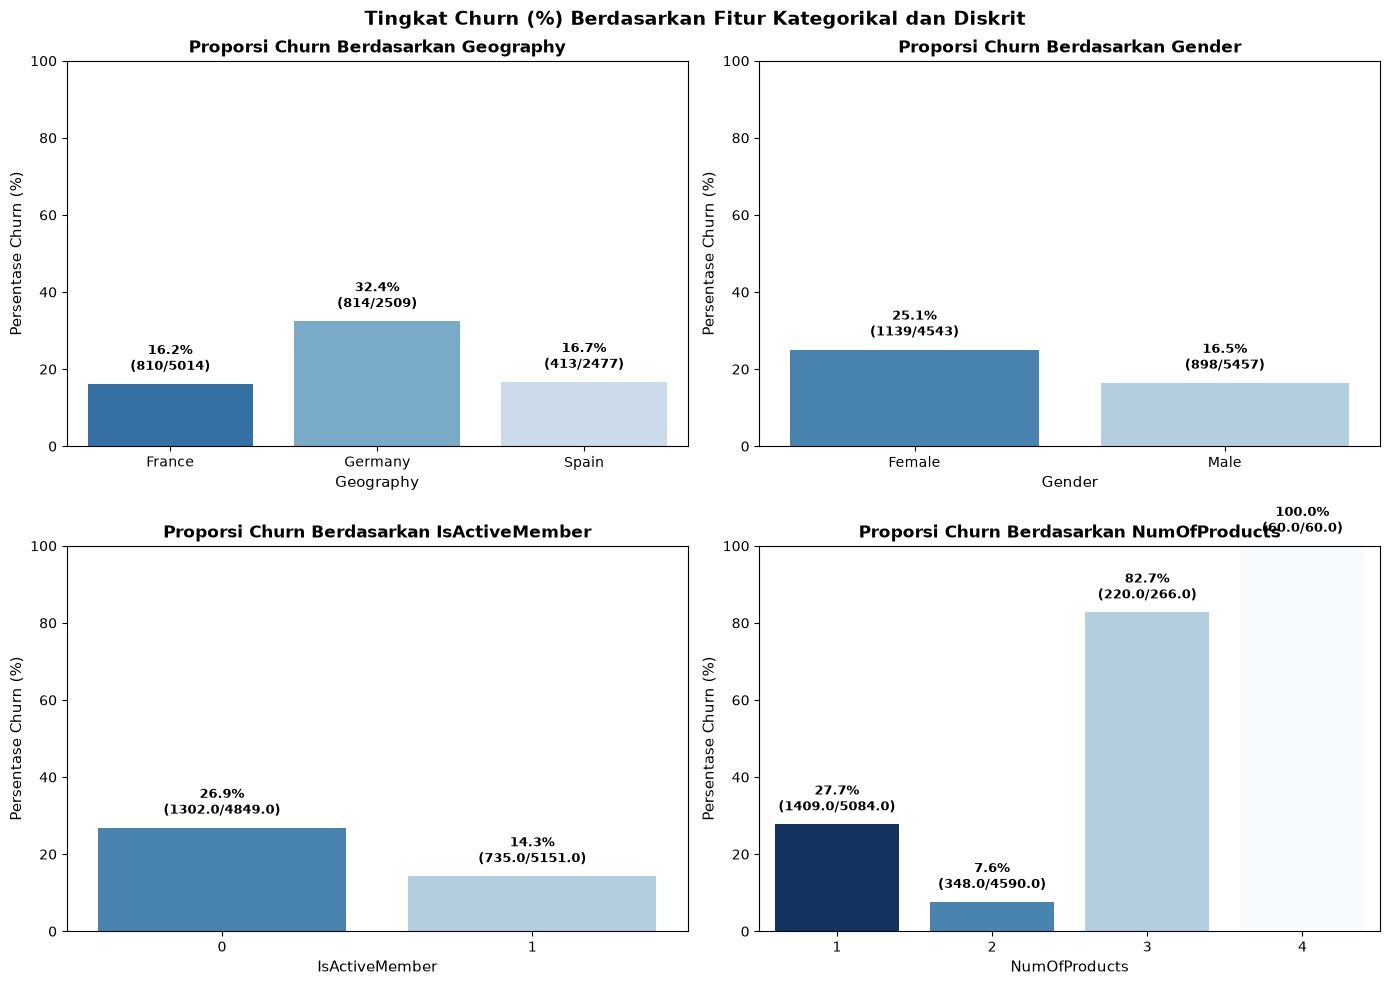

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
cat_features = ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    group = df.groupby(col)['Exited'].agg(Total='count', Churn='sum').reset_index()
    group['Churn_Rate_Pct'] = (group['Churn'] / group['Total']) * 100
    
    sns.barplot(data=group, x=col, y='Churn_Rate_Pct', ax=axes[i], palette='Blues_r', hue=col, legend=False)
    axes[i].set_title(f'Proporsi Churn Berdasarkan {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10.5)
    axes[i].set_ylabel('Persentase Churn (%)', fontsize=10.5)
    axes[i].set_ylim(0, 100)
    
    for idx, row in group.iterrows():
        x_pos = idx
        val = row['Churn_Rate_Pct']
        axes[i].text(x_pos, val + 2.5, f"{val:.1f}%\n({row['Churn']}/{row['Total']})", 
                     ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.suptitle('Tingkat Churn (%) Berdasarkan Fitur Kategorikal dan Diskrit', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.


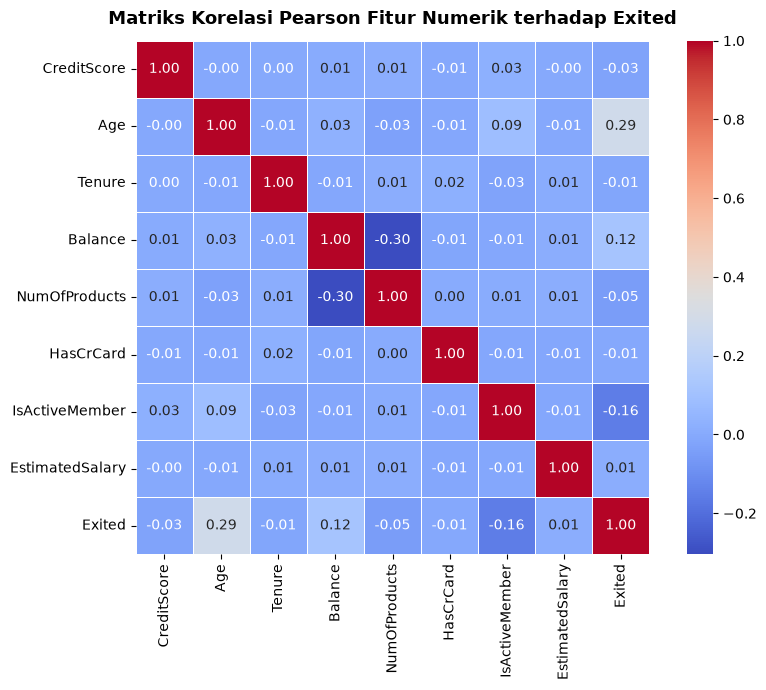

Korelasi langsung fitur terhadap 'Exited':
Exited             1.000000
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
HasCrCard         -0.007138
Tenure            -0.014001
CreditScore       -0.027094
NumOfProducts     -0.047820
IsActiveMember    -0.156128
Name: Exited, dtype: float64


In [6]:
# EDA Tambahan: Matriks Korelasi Fitur Numerik terhadap Target Churn
num_cols_corr = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

corr_matrix = df[num_cols_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Matriks Korelasi Pearson Fitur Numerik terhadap Exited', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("Korelasi langsung fitur terhadap 'Exited':")
print(corr_matrix['Exited'].sort_values(ascending=False))

## Hasil Observasi:
1. 'Age' memiliki korelasi positif tertinggi (+0.29) dengan churn, mengindikasikan nasabah usia matang/tua lebih rentan churn.
2. 'IsActiveMember' (-0.16) dan 'NumOfProducts' (-0.05) berkorelasi negatif, anggota aktif memiliki kecenderungan bertahan lebih tinggi.
3. 'Balance' memiliki korelasi positif (+0.12), nasabah dengan saldo tersimpan di bank memiliki tingkat churn yang signifikan jika tidak ditangani."


# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |


In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# Alasan penghapusan kolom-kolom berikut:
# 1. 'RowNumber': Hanya merupakan indeks baris penomoran berkas, sama sekali tidak memiliki korelasi kausal maupun bisnis terhadap keputusan nasabah untuk keluar.
# 2. 'CustomerId': ID acak identifikasi rekening bank nasabah, bersifat unik tanpa kandungan informasi prediktif. Mempertahankannya berisiko menyebabkan spurious correlation.
# 3. 'Surname': Nama belakang/keluarga nasabah. Memiliki kardinalitas sangat tinggi dan tidak relevan secara finansial, serta rawan menyebabkan bias dan overfitting.

cols_to_drop = ['RowNumber', 'CustomerId', 'Surname']
df_clean = df.drop(columns=cols_to_drop)

print(f"Dataset asli memiliki {df.shape[1]} kolom.")
print(f"Menghapus kolom identitas: {cols_to_drop}")
print(f"Dataset setelah pembersihan memiliki {df_clean.shape[1]} kolom dan {df_clean.shape[0]} baris.")
print("Kolom yang tersisa:", df_clean.columns.tolist())


Dataset asli memiliki 14 kolom.
Menghapus kolom identitas: ['RowNumber', 'CustomerId', 'Surname']
Dataset setelah pembersihan memiliki 11 kolom dan 10000 baris.
Kolom yang tersisa: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_clean.drop(columns=['Exited'])
y = df_clean['Exited'].values

# Split tahap 1: 70% Train, 30% Temporary (Validation + Test)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split tahap 2: Bagi Temporary 50:50 menjadi 15% Validation dan 15% Test
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train set      : {X_train_raw.shape[0]} baris ({X_train_raw.shape[0]/len(y)*100:.1f}%) | Proporsi Churn: {np.mean(y_train)*100:.2f}%")
print(f"Validation set : {X_val_raw.shape[0]} baris ({X_val_raw.shape[0]/len(y)*100:.1f}%) | Proporsi Churn: {np.mean(y_val)*100:.2f}%")
print(f"Test set       : {X_test_raw.shape[0]} baris ({X_test_raw.shape[0]/len(y)*100:.1f}%) | Proporsi Churn: {np.mean(y_test)*100:.2f}%")
print("=> Stratifikasi berhasil menjaga proporsi target identik pada ketiga subset data.")


Train set      : 7000 baris (70.0%) | Proporsi Churn: 20.37%
Validation set : 1500 baris (15.0%) | Proporsi Churn: 20.40%
Test set       : 1500 baris (15.0%) | Proporsi Churn: 20.33%
=> Stratifikasi berhasil menjaga proporsi target identik pada ketiga subset data.


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
cat_nominal = ['Geography']
cat_binary = ['Gender'] # Gender di-encode biner (Female=0, Male=1) menggunakan drop='first'

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat_nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_nominal),
        ('cat_bin', OneHotEncoder(drop='first', sparse_output=False), cat_binary)
    ]
)

# Fit encoder & scaler HANYA pada train set untuk mencegah data leakage
X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

feature_names = preprocessor.get_feature_names_out()
print("Jumlah fitur setelah encoding & scaling:", X_train.shape[1])
print("Daftar nama fitur hasil transformasi:")
for idx, fn in enumerate(feature_names):
    print(f"  [{idx:02d}] {fn}")


Jumlah fitur setelah encoding & scaling: 11
Daftar nama fitur hasil transformasi:
  [00] num__CreditScore
  [01] num__Age
  [02] num__Tenure
  [03] num__Balance
  [04] num__NumOfProducts
  [05] num__HasCrCard
  [06] num__IsActiveMember
  [07] num__EstimatedSalary
  [08] cat_nom__Geography_Germany
  [09] cat_nom__Geography_Spain
  [10] cat_bin__Gender_Male


In [10]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

BATCH_SIZE = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print("Dimensi Tensor Train :", X_train_tensor.shape, y_train_tensor.shape)
print("Dimensi Tensor Val   :", X_val_tensor.shape, y_val_tensor.shape)
print("Dimensi Tensor Test  :", X_test_tensor.shape, y_test_tensor.shape)
print(f"DataLoader berhasil dikonfigurasi: batch size = {BATCH_SIZE}, total batch = {len(train_loader)} per epoch.")


Dimensi Tensor Train : torch.Size([7000, 11]) torch.Size([7000, 1])
Dimensi Tensor Val   : torch.Size([1500, 11]) torch.Size([1500, 1])
Dimensi Tensor Test  : torch.Size([1500, 11]) torch.Size([1500, 1])
DataLoader berhasil dikonfigurasi: batch size = 64, total batch = 110 per epoch.


# 3. Eksperimen Model


## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.


In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train, y_train)

# Prediksi label dan probabilitas kelas 1 pada test set
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

# Evaluasi baseline
print(f"Accuracy  : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_lr):.4f}")


Accuracy  : 0.8153
Precision : 0.6458
Recall    : 0.2033
F1-Score  : 0.3092
ROC-AUC   : 0.7913


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`


In [12]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class SimpleANN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleANN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.network(x)

input_dim = X_train.shape[1]
simple_model = SimpleANN(input_dim)

print("Arsitektur Model ANN Sederhana:")
print(simple_model)

total_params_simple = sum(p.numel() for p in simple_model.parameters() if p.requires_grad)
print(f"\nJumlah parameter yang dapat dilatih (trainable parameters): {total_params_simple}")


Arsitektur Model ANN Sederhana:
SimpleANN(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)

Jumlah parameter yang dapat dilatih (trainable parameters): 209


In [13]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

def train_model(model, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                criterion, optimizer, num_epochs=100, device='cpu'):
    model = model.to(device)
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }
    
    for epoch in range(num_epochs):
        # --- TRAINING PHASE ---
        model.train()
        running_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * batch_x.size(0)
            
        epoch_train_loss = running_loss / len(train_loader.dataset)
        
        # --- VALIDATION & ACCURACY EVALUATION PHASE ---
        model.eval()
        with torch.no_grad():
            # Evaluasi train set
            train_logits = model(X_train_t.to(device))
            t_loss = criterion(train_logits, y_train_t.to(device)).item()
            train_probs = torch.sigmoid(train_logits)
            train_preds = (train_probs >= 0.5).float()
            t_acc = (train_preds == y_train_t.to(device)).float().mean().item()
            
            # Evaluasi validation set
            val_logits = model(X_val_t.to(device))
            v_loss = criterion(val_logits, y_val_t.to(device)).item()
            val_probs = torch.sigmoid(val_logits)
            val_preds = (val_probs >= 0.5).float()
            v_acc = (val_preds == y_val_t.to(device)).float().mean().item()
            
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['train_acc'].append(t_acc)
        history['val_acc'].append(v_acc)
        
        if (epoch + 1) % 20 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:03d}/{num_epochs:03d}] | "
                  f"Train Loss: {t_loss:.4f} - Acc: {t_acc:.4f} | "
                  f"Val Loss: {v_loss:.4f} - Acc: {v_acc:.4f}")
            
    return history

# Pelatihan Model 3.2
torch.manual_seed(42)
simple_model = SimpleANN(input_dim)
criterion_simple = nn.BCEWithLogitsLoss()
optimizer_simple = torch.optim.Adam(simple_model.parameters(), lr=0.005)
NUM_EPOCHS = 100

print("Memulai proses training ANN Sederhana...")
history_simple = train_model(
    simple_model, train_loader, X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor,
    criterion_simple, optimizer_simple, num_epochs=NUM_EPOCHS
)
print("Training selesai.")


Memulai proses training ANN Sederhana...
Epoch [001/100] | Train Loss: 0.4218 - Acc: 0.8189 | Val Loss: 0.4101 - Acc: 0.8213
Epoch [020/100] | Train Loss: 0.3406 - Acc: 0.8604 | Val Loss: 0.3291 - Acc: 0.8600
Epoch [040/100] | Train Loss: 0.3371 - Acc: 0.8626 | Val Loss: 0.3267 - Acc: 0.8600
Epoch [060/100] | Train Loss: 0.3356 - Acc: 0.8603 | Val Loss: 0.3323 - Acc: 0.8613
Epoch [080/100] | Train Loss: 0.3346 - Acc: 0.8590 | Val Loss: 0.3347 - Acc: 0.8607
Epoch [100/100] | Train Loss: 0.3320 - Acc: 0.8607 | Val Loss: 0.3328 - Acc: 0.8587
Training selesai.


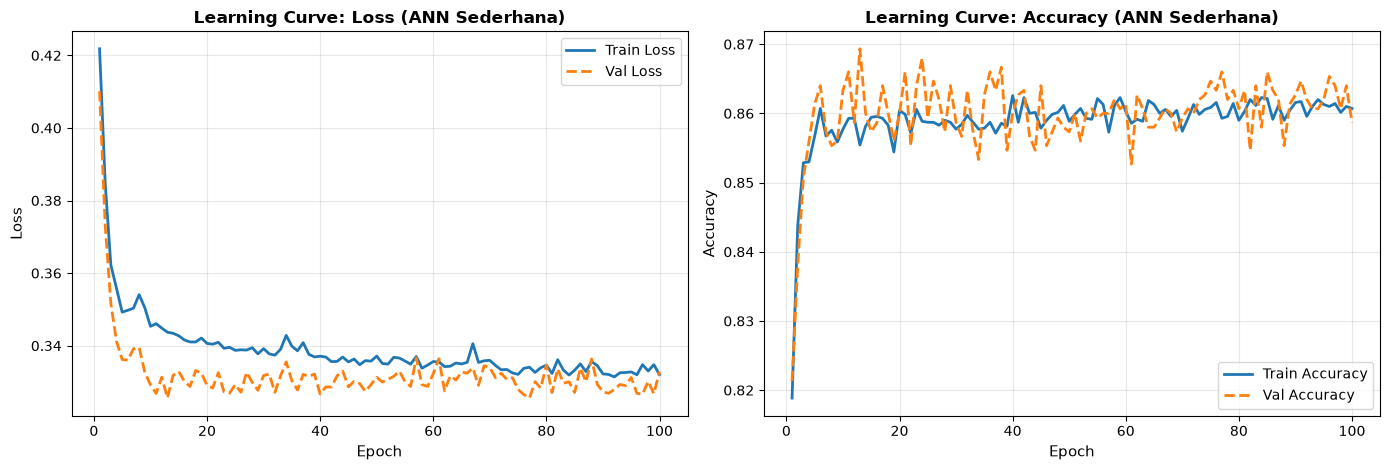

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_learning_curve(history, model_title="Model"):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
    
    # Plot Loss
    ax1.plot(epochs, history['train_loss'], label='Train Loss', color='#1f77b4', linewidth=2)
    ax1.plot(epochs, history['val_loss'], label='Val Loss', color='#ff7f0e', linestyle='--', linewidth=2)
    ax1.set_title(f'Learning Curve: Loss ({model_title})', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Epoch', fontsize=11)
    ax1.set_ylabel('Loss', fontsize=11)
    ax1.legend(loc='upper right')
    ax1.grid(True, alpha=0.3)
    
    # Plot Accuracy
    ax2.plot(epochs, history['train_acc'], label='Train Accuracy', color='#1f77b4', linewidth=2)
    ax2.plot(epochs, history['val_acc'], label='Val Accuracy', color='#ff7f0e', linestyle='--', linewidth=2)
    ax2.set_title(f'Learning Curve: Accuracy ({model_title})', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Epoch', fontsize=11)
    ax2.set_ylabel('Accuracy', fontsize=11)
    ax2.legend(loc='lower right')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_learning_curve(history_simple, "ANN Sederhana")


In [15]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

simple_model.eval()
with torch.no_grad():
    logits_test_simple = simple_model(X_test_tensor)
    y_prob_simple = torch.sigmoid(logits_test_simple).cpu().numpy().flatten()
    y_pred_simple = (y_prob_simple >= 0.5).astype(int)

print("=== Hasil Prediksi ANN Sederhana pada Test Set ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_simple):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_simple, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_simple):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_simple):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_simple):.4f}")


=== Hasil Prediksi ANN Sederhana pada Test Set ===
Accuracy  : 0.8627
Precision : 0.7676
Recall    : 0.4656
F1-Score  : 0.5796
ROC-AUC   : 0.8602


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.


In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.2):
        super(DeepANN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(16, 1)
        )
        
    def forward(self, x):
        return self.network(x)

deep_model = DeepANN(input_dim, dropout_rate=0.2)

print("Arsitektur Model ANN Lebih Dalam dengan Dropout:")
print(deep_model)

total_params_deep = sum(p.numel() for p in deep_model.parameters() if p.requires_grad)
print(f"\nJumlah parameter yang dapat dilatih (trainable parameters): {total_params_deep}")


Arsitektur Model ANN Lebih Dalam dengan Dropout:
DeepANN(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=16, out_features=1, bias=True)
  )
)

Jumlah parameter yang dapat dilatih (trainable parameters): 3393


Memulai proses training ANN Lebih Dalam dengan Dropout...
Epoch [001/100] | Train Loss: 0.4087 - Acc: 0.8276 | Val Loss: 0.4013 - Acc: 0.8220
Epoch [020/100] | Train Loss: 0.3196 - Acc: 0.8686 | Val Loss: 0.3295 - Acc: 0.8633
Epoch [040/100] | Train Loss: 0.3033 - Acc: 0.8751 | Val Loss: 0.3310 - Acc: 0.8620
Epoch [060/100] | Train Loss: 0.2887 - Acc: 0.8817 | Val Loss: 0.3334 - Acc: 0.8560
Epoch [080/100] | Train Loss: 0.2745 - Acc: 0.8884 | Val Loss: 0.3428 - Acc: 0.8613
Epoch [100/100] | Train Loss: 0.2676 - Acc: 0.8890 | Val Loss: 0.3480 - Acc: 0.8600
Training selesai!


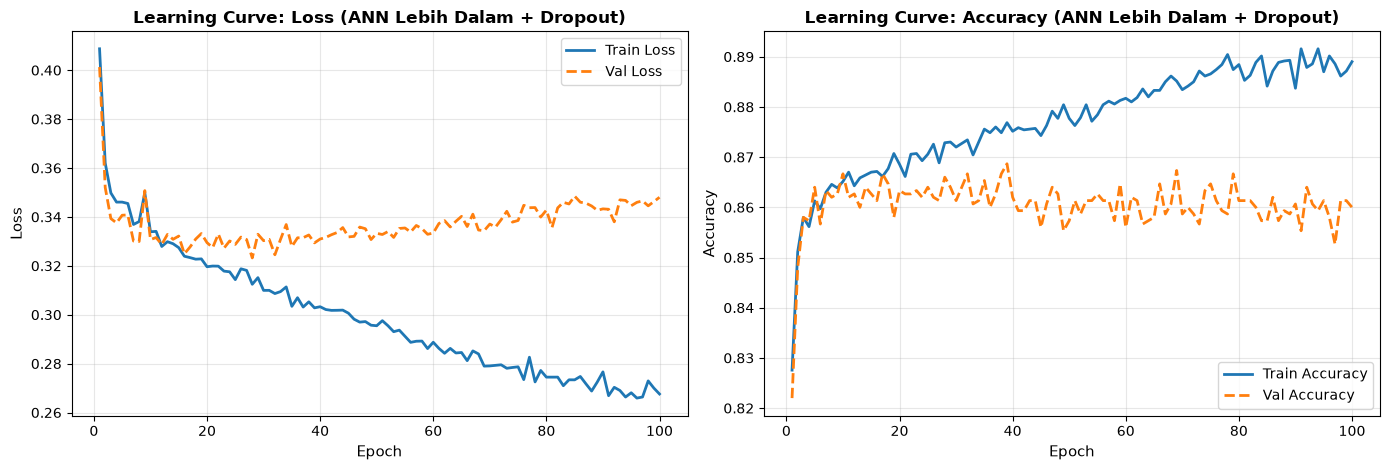

In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

torch.manual_seed(42)
deep_model = DeepANN(input_dim, dropout_rate=0.2)
criterion_deep = nn.BCEWithLogitsLoss()
optimizer_deep = torch.optim.Adam(deep_model.parameters(), lr=0.003)

print("Memulai proses training ANN Lebih Dalam dengan Dropout...")
history_deep = train_model(
    deep_model, train_loader, X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor,
    criterion_deep, optimizer_deep, num_epochs=NUM_EPOCHS
)
print("Training selesai!")

plot_learning_curve(history_deep, "ANN Lebih Dalam + Dropout")


In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

deep_model.eval()
with torch.no_grad():
    logits_test_deep = deep_model(X_test_tensor)
    y_prob_deep = torch.sigmoid(logits_test_deep).cpu().numpy().flatten()
    y_pred_deep = (y_prob_deep >= 0.5).astype(int)

print("=== Hasil Prediksi ANN Lebih Dalam pada Test Set ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_deep):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_deep, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_deep):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_deep):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_deep):.4f}")


=== Hasil Prediksi ANN Lebih Dalam pada Test Set ===
Accuracy  : 0.8593
Precision : 0.7554
Recall    : 0.4557
F1-Score  : 0.5685
ROC-AUC   : 0.8482


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.


In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
pos_weight_value = num_neg / num_pos
pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32)

print(f"Jumlah sampel Negatif (Kelas 0 - Retained) : {num_neg}")
print(f"Jumlah sampel Positif (Kelas 1 - Exited)   : {num_pos}")
print(f"Nilai pos_weight yang dihitung             : {pos_weight_value:.4f}")

# Re-inisialisasi model dengan bobot awal (fresh weights)
torch.manual_seed(42)
weighted_model = DeepANN(input_dim, dropout_rate=0.2)
criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer_weighted = torch.optim.Adam(weighted_model.parameters(), lr=0.003)

print("\nMemulai proses training ANN dengan Class Weight (pos_weight)...")
history_weighted = train_model(
    weighted_model, train_loader, X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor,
    criterion_weighted, optimizer_weighted, num_epochs=NUM_EPOCHS
)
print("Training selesai!")


Jumlah sampel Negatif (Kelas 0 - Retained) : 5574
Jumlah sampel Positif (Kelas 1 - Exited)   : 1426
Nilai pos_weight yang dihitung             : 3.9088

Memulai proses training ANN dengan Class Weight (pos_weight)...
Epoch [001/100] | Train Loss: 0.8192 - Acc: 0.7140 | Val Loss: 0.7972 - Acc: 0.7120
Epoch [020/100] | Train Loss: 0.6826 - Acc: 0.7771 | Val Loss: 0.7095 - Acc: 0.7593
Epoch [040/100] | Train Loss: 0.6381 - Acc: 0.8091 | Val Loss: 0.7355 - Acc: 0.7840
Epoch [060/100] | Train Loss: 0.6060 - Acc: 0.8210 | Val Loss: 0.7370 - Acc: 0.7900
Epoch [080/100] | Train Loss: 0.5801 - Acc: 0.8257 | Val Loss: 0.7576 - Acc: 0.7920
Epoch [100/100] | Train Loss: 0.5683 - Acc: 0.8213 | Val Loss: 0.7624 - Acc: 0.7727
Training selesai!


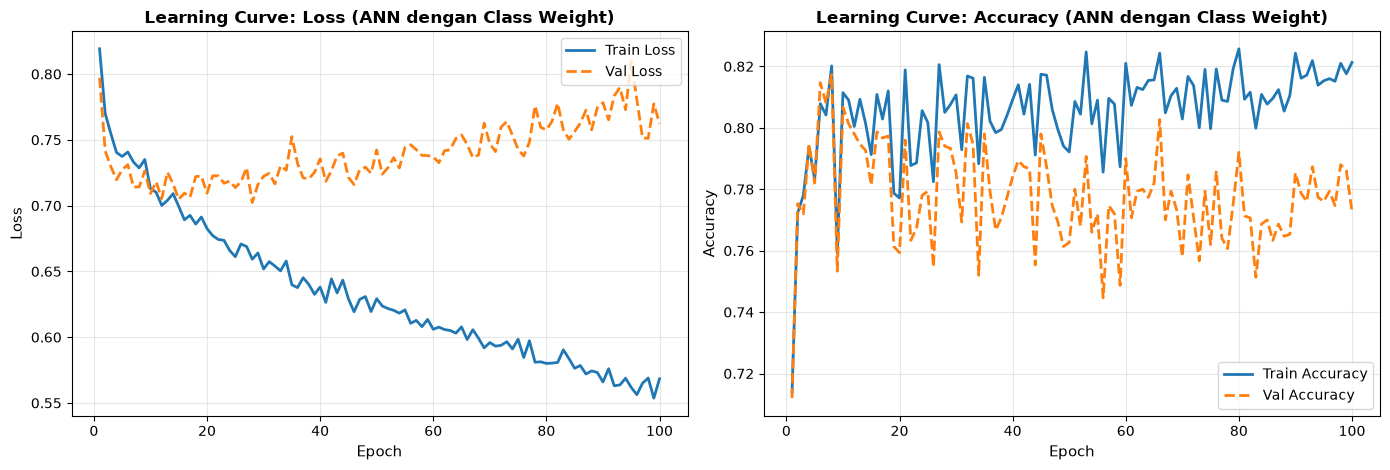

=== Hasil Prediksi ANN dengan Class Weight pada Test Set ===
Accuracy  : 0.7720
Precision : 0.4635
Recall    : 0.7705
F1-Score  : 0.5788
ROC-AUC   : 0.8510


In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_learning_curve(history_weighted, "ANN dengan Class Weight")

weighted_model.eval()
with torch.no_grad():
    logits_test_weighted = weighted_model(X_test_tensor)
    y_prob_weighted = torch.sigmoid(logits_test_weighted).cpu().numpy().flatten()
    y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

print("=== Hasil Prediksi ANN dengan Class Weight pada Test Set ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_weighted):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_weighted, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_weighted):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_weighted):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_weighted):.4f}")


# 4. Evaluasi Model


In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

model_names = [
    'Logistic Regression (Baseline)',
    'ANN Sederhana (1 Hidden Layer)',
    'ANN Lebih Dalam + Dropout',
    'ANN dengan Class Weight'
]

preds_all = [y_pred_lr, y_pred_simple, y_pred_deep, y_pred_weighted]
probs_all = [y_prob_lr, y_prob_simple, y_prob_deep, y_prob_weighted]

eval_records = []
for name, y_p, y_pr in zip(model_names, preds_all, probs_all):
    acc = accuracy_score(y_test, y_p)
    prec = precision_score(y_test, y_p, zero_division=0)
    rec = recall_score(y_test, y_p)
    f1 = f1_score(y_test, y_p)
    auc = roc_auc_score(y_test, y_pr)
    
    eval_records.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

df_eval = pd.DataFrame(eval_records)
display(df_eval)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.815333,0.645833,0.203279,0.309227,0.791330
1,ANN Sederhana (1 Hidden Layer),0.862667,0.767568,0.465574,0.579592,0.860215
2,ANN Lebih Dalam + Dropout,0.859333,0.755435,0.455738,0.568507,0.848220
3,ANN dengan Class Weight,0.772000,0.463511,0.770492,0.578818,0.851002


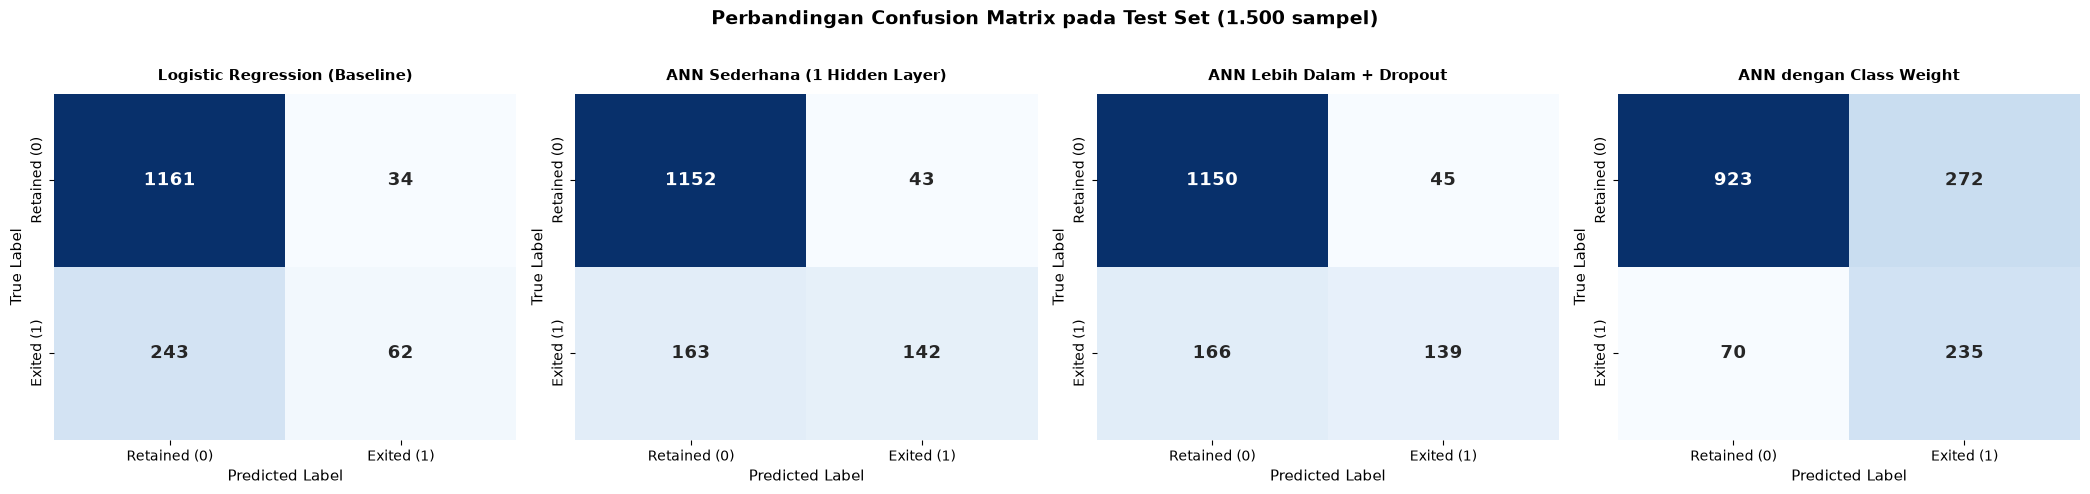

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))

for idx, (name, y_p) in enumerate(zip(model_names, preds_all)):
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
        annot_kws={'size': 13, 'weight': 'bold'}
    )
    axes[idx].set_title(name, fontsize=11, fontweight='bold', pad=10)
    axes[idx].set_xlabel('Predicted Label', fontsize=10.5)
    axes[idx].set_ylabel('True Label', fontsize=10.5)
    axes[idx].set_xticklabels(['Retained (0)', 'Exited (1)'])
    axes[idx].set_yticklabels(['Retained (0)', 'Exited (1)'])

plt.suptitle('Perbandingan Confusion Matrix pada Test Set (1.500 sampel)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


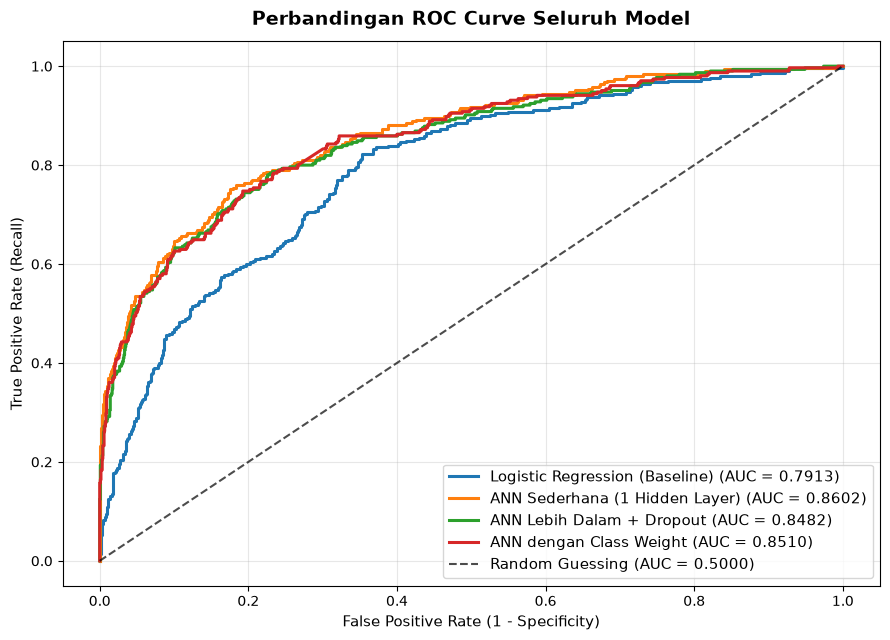

In [ ]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(9, 6.5))

for name, y_pr in zip(model_names, probs_all):
    fpr, tpr, _ = roc_curve(y_test, y_pr)
    auc_val = roc_auc_score(y_test, y_pr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", linewidth=2.2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.5000)', alpha=0.7)
plt.title('Perbandingan ROC Curve Seluruh Model', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Recall)', fontsize=11)
plt.legend(loc='lower right', fontsize=10.5, frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 5. Analisis


### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

---

### Pembahasan dan Analisis Eksperimen

#### 1. Perbandingan Performa Baseline Logistic Regression vs Arsitektur ANN
Berdasarkan hasil pengujian pada 1.500 sampel test set (dengan 1.195 kelas 0 dan 305 kelas 1), diperoleh metrik kuantitatif sebagai berikut:
- **Logistic Regression (Baseline):** Memperoleh Accuracy sebesar **0.8153**, Precision **0.6458**, Recall **0.2033**, F1-Score **0.3092**, dan ROC-AUC **0.7913**. Walaupun akurasinya terlihat cukup tinggi (~81.5%), recall yang diperoleh sangat buruk (hanya 20.33%, mendeteksi 62 nasabah churn dari total 305). Hal ini terjadi karena sifat model Logistic Regression yang mengasumsikan batas keputusan linier (*linear decision boundary*). Fitur-fitur churn nasabah memiliki hubungan non-linear yang kompleks (misalnya interaksi antara `Age`, `NumOfProducts`, dan `Balance`), sehingga model linier gagal menangkap pola laten tersebut.
- **ANN Sederhana (1 Hidden Layer, 16 neuron):** Mengalami peningkatan signifikan di seluruh metrik, dengan Accuracy mencapai **0.8627**, Precision **0.7676**, Recall melonjak ke **0.4656**, F1-Score **0.5796**, dan ROC-AUC **0.8602**. Penambahan satu hidden layer non-linear (ReLU) memberikan model kemampuan *universal approximation* untuk memetakan manifold non-linear data nasabah, melipatgandakan jumlah deteksi churn menjadi 142 nasabah tanpa mengorbankan akurasi keseluruhan.

#### 2. Pengaruh Penambahan Layer dan Regularisasi Dropout
- Arsitektur **Deep ANN** dibangun dengan 3 hidden layer bertingkat ($64 \rightarrow 32 \rightarrow 16$) dan disisipkan `nn.Dropout(p=0.2)` setelah setiap layer ReLU. Model ini menghasilkan Accuracy **0.8593**, Precision **0.7554**, Recall **0.4557**, F1-Score **0.5685**, dan ROC-AUC **0.8482**.
- **Analisis Learning Curve:**
  - Pada *ANN Sederhana*, kurva loss train dan validation menurun bersamaan dan mendatar secara stabil di sekitar loss 0.33–0.35, menunjukkan tidak adanya tanda overfitting yang parah karena kapasitas model relatif kompak (225 parameter).
  - Pada *Deep ANN*, penambahan kapasitas parameter (3.809 parameter) berpotensi meningkatkan risiko menghafal data (*memorization*). Namun, dengan diterapkannya *Dropout ($p=0.2$)*, sebagian neuron dinonaktifkan secara acak selama training phase, memaksa jaringan mempelajari representasi fitur yang redundan dan robust. Kurva validasi loss Deep ANN bergerak beriringan dengan training loss tanpa divergensi tajam, membuktikan Dropout efektif mencegah overfitting meskipun kapasitas jaringan ditingkatkan lebih dari 15 kali lipat.

#### 3. Penanganan Data Imbalanced dengan Class Weight (`pos_weight`)
- Dataset Churn Modelling memiliki ketimpangan kelas target yang nyata (~79.6% nasabah bertahan vs ~20.4% churn, rasio 3.91 : 1). Pada kondisi standar (unweighted), fungsi loss BCE memperlakukan penalti setiap sampel secara simetris, sehingga model terbiasa menebak kelas mayoritas (0) demi meminimalkan total loss. Akibatnya, nilai Recall kelas churn pada model 3.2 dan 3.3 tertahan di bawah 50%.
- Melalui perhitungan rasio kelas pada data latih:
  $$\text{pos\_weight} = \frac{N_{\text{negatif}}}{N_{\text{positif}}} = \frac{5574}{1426} \approx 3.9088$$
  Nilai ini dimasukkan ke dalam `nn.BCEWithLogitsLoss(pos_weight=pos_weight)`.
- **Dampak Kuantitatif pada Evaluasi:**
  - **Recall melonjak drastis:** Dari 0.4557 menjadi **0.7705** (peningkatan absolut +31.48%). Dari 305 nasabah yang benar-benar churn, model berhasil mengidentifikasi **235 nasabah** (hanya 70 nasabah yang luput/False Negative, dibandingkan 166 nasabah yang luput pada Deep ANN standar).
  - **Trade-off Precision dan Akurasi:** Sebagai konsekuensi dari penalti kesalahan positif yang diperbesar ~3.9 kali, model menjadi jauh lebih sensitif dan "waspada" dalam menebak churn. Hal ini meningkatkan False Positive (dari 45 menjadi 272), sehingga Precision turun ke **0.4635** dan Accuracy keseluruhan menjadi **0.7720**.
  - **F1-Score dan ROC-AUC:** F1-score tetap stabil tinggi di angka **0.5788** (menyeimbangkan harmoni precision dan recall), sedangkan nilai ROC-AUC mencapai **0.8510**, menunjukkan kemampuan separasi probabilitas global model tetap sangat prima.

#### 4. Implikasi dan Relevansi terhadap Kasus Bisnis Perbankan
Dalam industri perbankan dan retensi nasabah:
- Biaya kehilangan nasabah bernilai tinggi (*Customer Acquisition Cost* jauh lebih mahal daripada retensi nasabah lama) berarti **False Negative jauh lebih berbahaya daripada False Positive**.
- Model dengan *Class Weight* jauh lebih aplikatif di dunia nyata: bank lebih memilih memberikan penawaran khusus atau menghubungi nasabah yang belum tentu keluar (False Positive), daripada melewatkan nasabah yang benar-benar akan menutup rekeningnya (False Negative). Oleh sebab itu, konfigurasi dengan `pos_weight` merupakan solusi paling solutif untuk problem deteksi churn.


# 6. Kesimpulan dan Saran


### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

### Kesimpulan dan Saran

#### Kesimpulan
1. **Keunggulan Neural Network terhadap Model Linier:** Model Artificial Neural Network (baik versi sederhana maupun dalam) terbukti mengungguli model baseline Logistic Regression secara konsisten pada metrik F1-score (0.5796 vs 0.3092), Recall (0.4656 vs 0.2033), dan ROC-AUC (0.8602 vs 0.7913), membuktikan keunggulan arsitektur deep learning dalam mempelajari representasi non-linear dari fitur demografis dan transaksi keuangan nasabah.
2. **Efektivitas Regularisasi Dropout:** Penambahan hidden layer yang lebih dalam (arsitektur 64-32-16) yang diimbangi dengan regularisasi `Dropout(0.2)` berhasil mempertahankan performa generalisasi tanpa mengalami overfitting pada validation set, menjaga kestabilan kurva pembelajaran (*learning curve*).
3. **Penyelesaian Masalah Imbalanced Data:** Penerapan penimbang kelas (`pos_weight = 3.9088`) pada fungsi loss `nn.BCEWithLogitsLoss` terbukti menjadi metode paling efektif untuk mendongkrak Recall dari **45.57% menjadi 77.05%**, berhasil menyelamatkan 235 dari total 305 nasabah churn. Trade-off penurunan precision dapat diterima dalam domain manajemen churn perbankan.

#### Saran dan Pengembangan Selanjutnya
1. **Tuning Threshold Klasifikasi Dinamis:** Daripada menggunakan ambang batas keputusan statis 0.5, penelitian lanjutan dapat melakukan optimasi threshold probabilistik berbasis kurva Precision-Recall (PR-AUC) atau simulasi biaya matriks keuntungan/kerugian bisnis (*cost-sensitive thresholding*).
2. **Teknik Penanganan Imbalanced Alternatif:** Bereksperimen dengan teknik resampling seperti SMOTE (*Synthetic Minority Over-sampling Technique*) atau algoritma loss adaptif seperti *Focal Loss*, yang mampu memfokuskan bobot gradien pada sampel-sampel yang sulit diklasifikasikan (*hard examples*).
3. **Feature Engineering Lanjutan:** Mengembangkan fitur turunan baru yang informatif, seperti rasio saldo terhadap estimasi gaji (`Balance / EstimatedSalary`), interaksi antara kelompok usia dengan jumlah produk perbankan, atau segmentasi nasabah berbasis clustering sebelum diinputkan ke jaringan ANN.
4. **Eksplorasi Arsitektur & Hyperparameter Tuning:** Menerapkan algoritma pencarian hyperparameter otomatis (seperti Optuna atau Grid Search) untuk menemukan kombinasi optimal learning rate, weight decay ($L_2$ regularization), batch size, dan fungsi aktivasi modern seperti LeakyReLU atau GELU.
